# Notation and Symbols — the master reference

**Part:** Reference · **Reading time:** dip in as needed (~20 min for a full read) · **Pass 1 overview:** [What MRI measures](../pass1_big_picture/P1.1_What_MRI_Measures.ipynb) · **Refreshers you may want:** [Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb)

MRI borrows symbols from physics, electrical engineering, signal processing and medicine — and these four communities do not agree on notation. This notebook is the **single source of truth** for every symbol used in this series: what it means in plain words, its SI unit, a realistic number, and the chapter where it is first explained. When a chapter's own "Symbols used in this chapter" table and this page disagree, this page wins (and please treat the disagreement as a bug).

How to use it:

* Look up a symbol in the grouped tables of **section 4** (use your browser's search, Ctrl+F, for e.g. `T_2^*` or "dwell").
* Read **section 3 (Conventions)** once: it fixes the sign of precession, the sign of the Fourier transform and the meaning of "lab frame" vs "rotating frame". Almost every factor-of-$2\pi$ or sign error in MRI comes from mixing conventions.
* Read **section 5 (Symbol clashes)** before you read papers: the same letter means different things in different chapters.
* Section 1 lists the **corrections** to the original notation, section 2 defines the basic **vector and complex objects**, section 6 is a **units & prefixes cheat sheet** and section 7 a small **runnable unit converter**.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Corrections to the original notation chapter

The original book's notation table ("MRI Notation and Terminology") contained a few errors that this series fixes everywhere:

| Original | Problem | What we use |
|---|---|---|
| $T_1, T_2, T_2^*$ listed as "relaxation **rates**" | They are **time constants** (unit s). A *rate* is the inverse of a time constant. | $T_1,T_2,T_2^*$ = relaxation time constants [s]; $R_1=1/T_1$, $R_2=1/T_2$, $R_2^*=1/T_2^*$ = relaxation rates [s⁻¹] |
| Units of $\vec M$, $M_{XY}$, $M_0$ given as [T] | Magnetization is magnetic moment per volume, unit **A/m** (J T⁻¹ m⁻³). Only $\mu_0\vec M$ has units of tesla. | [A/m]; in all simulations we normalize $M_0=1$ (dimensionless) |
| Spin quantum number written $I_Z$ | $I_Z$ is the *z-component of the spin operator*, not the spin number. | $I$ (= 1/2 for ¹H) |
| Boltzmann constant written $k$ | $k$ is also used for k-space. | $k_B$ |
| Mixed upper/lower-case subscripts ($M_{XY}$, $G_X$) | Harmless but inconsistent. | Either is accepted; we write $M_{xy}$, $G_x$ in new text. |
| $B_1^+$ "typically in units of millitesla" (MRI System chapter) | RF amplitudes are **microtesla**. | $B_1 \approx 1$–$25\ \mu$T |
| Chemical shielding written $B_{eff}=B_0(1+\sigma)$ (In Vivo Spin Physics) | Shielding *reduces* the field felt by the nucleus. | $B_{eff}=B_0(1-\sigma)$ |

## 2. Vectors, complex numbers and fields — the basic objects

**Position** is a column vector (the superscript $T$ means transpose):

$$\vec r = \begin{bmatrix} x \\ y \\ z \end{bmatrix} = [x, y, z]^T .$$

In words: three coordinates in metres. By convention $z$ points along the main field $B_0$ (the long axis of the bore). For a patient lying supine, head first: $x$ = left–right, $y$ = anterior–posterior (front–back), $z$ = head–foot.

**Net magnetization** — a vector that can vary in space and time:

$$\vec M(\vec r,t) = \begin{bmatrix} M_x(\vec r,t) \\ M_y(\vec r,t) \\ M_z(\vec r,t) \end{bmatrix}.$$

In words: at every location $\vec r$ and time $t$, $\vec M$ is the sum of all nuclear magnetic moments in a small volume divided by that volume (unit A/m; we normalize to $M_0=1$). $M_z$ is the **longitudinal** component (along $B_0$), $M_x$ and $M_y$ form the **transverse** components.

**Transverse magnetization as one complex number** (see [complex-number refresher](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)):

$$M_{xy}(\vec r,t) = M_x(\vec r,t) + i\,M_y(\vec r,t), \qquad i=\sqrt{-1}.$$

In words: we pack the two transverse components into one complex number. Its magnitude $|M_{xy}|$ is the length of the transverse part (what produces signal) and its angle $\phi=\angle M_{xy}=\operatorname{atan2}(M_y,M_x)$ is the **phase** — the direction it points in the $x$–$y$ plane.

**Magnetic field (flux density)** — also a vector function of space and time:

$$\vec B(\vec r,t) = \begin{bmatrix} B_x(\vec r,t) \\ B_y(\vec r,t) \\ B_z(\vec r,t) \end{bmatrix}
= \begin{bmatrix} B_{1,x}^{lab}(\vec r,t) \\ B_{1,y}^{lab}(\vec r,t) \\ B_0 + \Delta B_0(\vec r) + \vec G(t)\cdot\vec r \end{bmatrix}.$$

In words: the $z$-component is the big static field $B_0$ plus small imperfections $\Delta B_0$ plus the gradient field $\vec G\cdot\vec r$ (all three point along $z$); the $x$ and $y$ components are the RF field, which oscillates at ≈ the Larmor frequency.

**Complex RF envelope.** In the lab frame the RF field rotates at $\omega_0$; we describe it by a slowly varying complex envelope $b_1(t)=B_{1,x}(t)+iB_{1,y}(t)$ defined in the **rotating frame**:

$$B_{1,x}^{lab}(t) + i\,B_{1,y}^{lab}(t) = b_1(t)\,e^{-i\omega_0 t}.$$

In words: the envelope $b_1$ tells you the amplitude (µT) and phase (direction) of the RF; the factor $e^{-i\omega_0 t}$ makes it rotate clockwise at the Larmor frequency, exactly like the spins (see section 3). *Note:* the original book's lab-frame expression (Magnetic Fields chapter) corresponds to the envelope $B_{1,x}-iB_{1,y}$; with our convention, $b_1$ in the rotating frame is precisely what `mt.bloch_simulate(B1=...)` takes.

## 3. Conventions (identical to `mri_tools.py`)

| Topic | Convention used in this series | Why it matters |
|---|---|---|
| Bloch equation | $\dfrac{d\vec M}{dt} = \gamma\,\vec M\times\vec B - \dfrac{M_x\hat x + M_y\hat y}{T_2} - \dfrac{(M_z-M_0)\hat z}{T_1}$ | Sign of $\gamma\vec M\times\vec B$ fixes the precession direction. |
| Direction of precession | **Left-handed (clockwise)** seen from the tip of $\vec B$ looking back, for $\gamma>0$ (¹H): $M_{xy}(t)=M_{xy}(0)\,e^{-i\omega_0 t}$ | A spin with positive off-resonance $\Delta f$ accumulates phase $\phi(t)=-2\pi\Delta f\,t$. |
| Rotation matrices | `mt.Rx`, `mt.Ry`, `mt.Rz` are the ordinary **right-handed** matrices of linear algebra; `mt.bloch_rotate` uses angle $\to -$angle | Read the sign of rotation angles in derivations carefully. |
| Lab vs rotating frame | **Lab frame**: fixed to the scanner. **Rotating frame**: $x', y'$ axes rotate clockwise about $z$ at the RF (≈ Larmor) frequency; $M_{xy}^{rot}=M_{xy}^{lab}e^{+i\omega_{rf}t}$. The $z$-axis is the same in both. | In the rotating frame $B_0$ "disappears"; only off-resonance $\Delta\omega/\gamma$, gradients and $b_1$ remain. Every chapter states which frame a formula is in. |
| Frequency | $f$ in Hz (cycles/s); angular frequency $\omega=2\pi f$ in rad/s | $\omega_0=\gamma B_0$ but $f_0=\bar\gamma B_0$ — never mix $\gamma$ and $\bar\gamma$. |
| Fourier transform | $F(k)=\displaystyle\int f(x)\,e^{-i2\pi kx}\,dx$, $\;f(x)=\displaystyle\int F(k)\,e^{+i2\pi kx}\,dk$ ($k$ in cycles/m, no $2\pi$ prefactors) | Matches Nishimura and Larson; `mt.fftc`/`mt.ifftc` are the centered discrete versions. See [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb). |
| Signal equation | $s(t)=\displaystyle\int m(\vec r)\,e^{-i2\pi\vec k(t)\cdot\vec r}\,d\vec r = M(\vec k(t))$, with $\vec k(t)=\bar\gamma\displaystyle\int_0^t\vec G(\tau)\,d\tau$ | The received (demodulated) signal is the Fourier transform of the image evaluated along the k-space trajectory. |
| Imaginary unit | $i=\sqrt{-1}$ (engineers write $j$) | — |
| Vectors | $\vec{\ }$ arrows (as in the original); bold upright $\mathbf E,\mathbf F,\mathbf x$ for matrices / vectorized images in reconstruction chapters | — |
| Discrete images | Centered FFT: $k=0$ and $x=0$ at index $N/2$ | Matches the way images and k-space are displayed. |

> **⚠️ Common confusion:** many textbooks (and the original book in places) draw counter-clockwise precession or use $e^{+i\omega t}$. Physics does not change, but signs in phase formulas do. If a formula from another source disagrees with ours by a sign of a phase, check its precession convention first.

## 4. The master symbol table (grouped)

Column "First appears in" points to the Pass-2 (or refresher) notebook where the symbol is introduced and explained. Typical values are for ¹H at 1.5–3 T in humans unless noted.

### 4.1 Geometry and time

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $\vec r=[x,y,z]^T$ | position in space | m | head ≈ 0.2 m across | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $x,\ y,\ z$ | scanner axes; $z$ along $B_0$ (bore axis), $x$ left–right, $y$ anterior–posterior (supine, head first) | m | isocenter = origin | [B2](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) |
| $\hat x,\hat y,\hat z$ | unit vectors along the axes | – | | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| $t$ | time | s | | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $\tau$ | dummy integration variable; in spin echoes also the 90°–180° spacing ($\tau = TE/2$) — context | s | | [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) |
| $d\vec r = dx\,dy\,dz$ | volume element in integrals | m³ | | [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) |
| $\delta_x\delta_y\delta_z$ | voxel volume ("Voxel Volume") | m³ | $1\ \mathrm{mm}^3 = 10^{-9}$ m³ | [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) |
| logical axes RO / PE / SS | readout, phase-encode, slice-select directions; can be rotated to any physical direction | – | "oblique" slices combine $G_x,G_y,G_z$ | [F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |

### 4.2 Magnetic fields

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $\vec B(\vec r,t)$ | magnetic flux density, colloquially "magnetic field" | T | 1 T = 10 000 gauss; Earth ≈ 50 µT | [B2](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) |
| $B_x, B_y, B_z$ | components of $\vec B$ | T | | [B2](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) |
| $\lVert\vec B\rVert$ | magnitude of $\vec B$ (sets the precession frequency) | T | | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $B_0$ | main static field (along $z$) | T | 0.55, 1.5, 3, 7 T (research: 9.4–11.7 T) | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $\Delta B_0(\vec r)$ | deviation of the static field from $B_0$ (magnet imperfection + susceptibility) | T | < 1 ppm (magnet) to ~10 ppm (air–tissue) | [A3](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) |
| $B_{eff}$ | field actually felt by a nucleus after electron shielding, $B_{eff}=B_0(1-\sigma)$ | T | | [A3](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) |
| $B_1(t)$ | RF magnetic field (transverse, ≈ Larmor frequency) | T | 1–25 µT | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $b_1(t)=B_{1,x}+iB_{1,y}$ | complex RF envelope in the rotating frame | T | | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| $B_{1,0}$, $B_{1,max}$ | amplitude of a hard (rectangular) pulse; peak RF amplitude allowed by the amplifier | T | hard 90° of 1 ms: 5.9 µT | [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb) |
| $B_1^+(\vec r)$ | transmit field: the co-rotating circularly polarized part that actually tips spins (per unit drive) | T | inhomogeneous by ±20–50 % at 3–7 T | [B1](../pass2_deep_dive/B1_MRI_System.ipynb) |
| $B_1^-(\vec r)$ | receive sensitivity of a coil (field per unit current, by reciprocity); ∝ $C_n$ | T/A | | [B1](../pass2_deep_dive/B1_MRI_System.ipynb) |
| $\vec G(t)=[G_x,G_y,G_z]^T$ | gradient: rate of change of $B_z$ with position, $B_z=B_0+\vec G\cdot\vec r$ | T/m | 20–80 mT/m clinical; 200–300 mT/m on special research systems | [B1](../pass2_deep_dive/B1_MRI_System.ipynb) |
| $G_{max}$ | maximum gradient amplitude per axis | T/m | 40–80 mT/m | [B4](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb) |
| $SR$ | slew rate = maximum $dG/dt$ | T/m/s | 100–200 T/m/s | [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) |
| $t_{rise}=G_{max}/SR$ | time to ramp a gradient from 0 to $G_{max}$ | s | 0.2–0.5 ms | [B4](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb) |
| $\vec H$ | magnetic field strength ($\vec B=\mu_0(\vec H+\vec M)$) — rarely used in MRI | A/m | not to be confused with $\vec B$ | [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb) |
| $\Phi_B$ | magnetic flux through a coil, $\Phi_B=\int\vec B\cdot d\vec A$ | Wb = T m² | see clash with phase $\Phi$ | [RP2](../refreshers/RP2_Induction_and_RF.ipynb) |
| $\chi$ | (volume) magnetic susceptibility; $\vec M_{induced}=\chi\vec H$ | – (SI) | water −9.05×10⁻⁶; air +0.36×10⁻⁶ | [A3](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) |
| $\nabla B$, $dB/dz$ (fringe) | spatial gradient of the *static* fringe field (pulls magnetic objects) | T/m | several T/m near the bore entrance; clash with imaging $G$ | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |

### 4.3 Spin physics and physical constants

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $\gamma$ | gyromagnetic ratio (angular version): precession rate per tesla | rad s⁻¹ T⁻¹ | $2.675\times10^8$ for ¹H | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| $\bar\gamma=\gamma/2\pi$ | "gamma-bar": precession frequency per tesla | Hz/T | 42.577 MHz/T (¹H); see table in section 7 | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $\omega_0=\gamma B_0$ | Larmor angular frequency | rad/s | $8.03\times10^8$ rad/s at 3 T | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| $f_0=\bar\gamma B_0$ | Larmor (resonance) frequency | Hz | 63.9 MHz @ 1.5 T, 127.7 MHz @ 3 T, 298 MHz @ 7 T | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $\omega=2\pi f$ | angular frequency vs ordinary frequency | rad/s vs Hz | | [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb) |
| $\vec\mu$ | magnetic moment of one nucleus | J/T (= A m²) | ¹H: $1.41\times10^{-26}$ J/T | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $I$ | spin quantum number (original wrote $I_Z$) | – | 1/2 for ¹H, ¹³C, ¹⁹F, ³¹P; 1 for ²H; 3/2 for ²³Na; 0 for ¹²C, ¹⁶O | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $m_I$ | magnetic quantum number (which energy level), $m_I=-I,\dots,+I$ | – | ±1/2 for ¹H | [RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb) |
| $h$ | Planck constant | J s (= J/Hz) | $6.626\times10^{-34}$ | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $\hbar=h/2\pi$ | reduced Planck constant | J s | $1.055\times10^{-34}$ | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $k_B$ | Boltzmann constant (original writes $k$) | J/K | $1.381\times10^{-23}$ J/K $=8.617\times10^{-5}$ eV/K | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $T$ (no subscript) | absolute temperature | K | body 310 K | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $N(\vec r)$ | spin density: number of nuclei per volume | m⁻³ | water ¹H ≈ $6.7\times10^{28}$ m⁻³ | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $N_\uparrow,\ N_\downarrow$ | number of spins in the lower ("up", parallel) / upper ("down") energy state | – | | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $\Delta E=h\bar\gamma B_0=\hbar\gamma B_0$ | energy gap between the two spin states | J | $8.5\times10^{-26}$ J ≈ 0.5 µeV at 3 T | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $P=\dfrac{N_\uparrow-N_\downarrow}{N_\uparrow+N_\downarrow}$ | fractional polarization | – | ≈ 10 ppm ($10^{-5}$) at 3 T, 310 K | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $N_A$ | Avogadro constant | mol⁻¹ | $6.022\times10^{23}$ | [RP4](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb) |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}\approx1.257\times10^{-6}$ | [RP1](../refreshers/RP1_Magnetism_from_Currents.ipynb) |
| $c$ | speed of light | m/s | $3.0\times10^8$ | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |

### 4.4 Magnetization and relaxation

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $\vec M(\vec r,t)=[M_x,M_y,M_z]^T$ | net magnetization = sum of moments per volume | A/m (we normalize $M_0=1$) | | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $M_{xy}=M_x+iM_y$ | transverse magnetization as a complex number | same as $\vec M$ | | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| $\lvert M_{xy}\rvert$, $\phi=\angle M_{xy}$ | magnitude and phase of transverse magnetization | –, rad | | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| $M_z$ | longitudinal magnetization | same | | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $M_0(\vec r)$ | equilibrium magnetization ("proton density" weighting) | same | ≈ $10^{-2}$ A/m for water at 3 T ($\mu_0M_0\approx 12$ nT) | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $T_1$ | longitudinal (spin–lattice) relaxation **time constant** | s | 0.25–4 s (fat ≈ 0.3–0.4 s, CSF ≈ 4 s) | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $T_2$ | transverse (spin–spin) relaxation **time constant** | s | 10 ms – 2 s (brain ≈ 70–100 ms) | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $T_2^*$ | effective transverse relaxation time incl. intravoxel dephasing; $T_2^*\le T_2$ | s | brain ≈ 40–60 ms at 3 T | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $T_2'$ | extra dephasing from field inhomogeneity: $1/T_2^*=1/T_2+1/T_2'$ | s | | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $R_1=1/T_1$, $R_2=1/T_2$, $R_2^*=1/T_2^*$, $R_2'=1/T_2'$ | relaxation **rates** | s⁻¹ | | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $E_1=e^{-TR/T_1}$, $E_2=e^{-TR/T_2}$ | shorthands in steady-state formulas | – | | [D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb) |
| $r_1,\ r_2$ | relaxivities of a contrast agent: $1/\hat T_{1}=1/T_{1}+r_1[CM]$ | L mmol⁻¹ s⁻¹ (= mM⁻¹ s⁻¹) | Gd agents $r_1\approx$ 3–5 mM⁻¹s⁻¹ at 1.5 T | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $[CM]$ | contrast-agent concentration | mmol/L (mM) | ≈ 0.1–1 mM in tissue; dose 0.1 mmol/kg | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $\hat T_1,\hat T_2$ | relaxation times in the presence of contrast agent | s | | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $D$, $ADC$ | diffusion coefficient; *apparent* diffusion coefficient measured in tissue | m²/s (often mm²/s) | free water 37 °C: $3\times10^{-9}$ m²/s; brain ≈ $0.8\times10^{-9}$ | glossary only ([Glossary](Glossary_and_Acronyms.ipynb)) |
| $b$ | diffusion weighting ("b-value") | s/m² (quoted in s/mm²) | 0–1000 s/mm² clinical | glossary only ([Glossary](Glossary_and_Acronyms.ipynb)) |

### 4.5 RF pulses

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $\theta$ | flip angle: how far the RF tips $\vec M$ (many books use $\alpha$) | rad (or °) | 5°–180° | [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) |
| $\omega_1=\gamma B_1$, $f_1=\bar\gamma B_1$ | nutation (tipping) rate caused by the RF | rad/s, Hz | 5.9 µT → 250 Hz | [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb) |
| $T_{rf}$ | RF pulse duration | s | 0.1–10 ms | [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb) |
| $BW_{rf}$ | RF pulse bandwidth (range of frequencies excited) | Hz | 1–5 kHz | [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb) |
| $TBW=T_{rf}\cdot BW_{rf}$ | time–bandwidth product (fixed by the pulse *shape*; higher = sharper profile) | – | 2–12 | [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb) |
| $f_{rf}$, $\omega_{rf}$ | RF carrier frequency (defines the rotating frame) | Hz, rad/s | ≈ $f_0$ | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| $\phi_{rf}$ | RF phase (direction of $b_1$ in the rotating frame, e.g. "90°ₓ") | rad | | [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb) |
| $f_{off}$ | RF frequency offset used to shift the slice | Hz | | [E2](../pass2_deep_dive/E2_Slice_Selection.ipynb) |
| $\delta_1,\ \delta_2$ | passband / stopband ripple of a designed pulse profile (SLR design) | – | 0.01 | [E3](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb) |
| $SAR$ | specific absorption rate: RF power absorbed per kg of tissue | W/kg | limits: 2 W/kg whole body, 3.2 W/kg head (normal mode) | [E1](../pass2_deep_dive/E1_RF_Pulses.ipynb) |
| $SED$ | specific energy dose = SAR × time | J/kg | | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| $\Delta\omega=2\pi\Delta f$ | off-resonance in the rotating frame (appears as a $z$-field $\Delta\omega/\gamma$) | rad/s | | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |
| $\vec B_{eff}^{rot}=[B_{1,x},B_{1,y},\Delta\omega/\gamma]^T$ | effective field in the rotating frame during RF | T | | [A2](../pass2_deep_dive/A2_Bloch_Equation.ipynb) |

### 4.6 Sequence timing

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $TE$ | echo time: excitation centre → echo (centre of k-space) | s | 1–100 ms (T2w FSE up to ~120 ms) | [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) |
| $TR$ | repetition time between successive excitations of the same slice | s | 3 ms (bSSFP) – 10 s | [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) |
| $TI$ | inversion time: 180° inversion → excitation | s | STIR ≈ 150–250 ms, FLAIR ≈ 2–2.5 s | [D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb) |
| $TE_{eff}$ | effective TE: when the centre of k-space is acquired in an echo train | s | | [H2](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) |
| $t_{esp}$ (ESP) | echo spacing in an echo train | s | FSE 5–15 ms, EPI 0.3–1 ms | [H2](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) |
| $ETL$ | echo train length (echoes / k-space lines per excitation) | – | 4–32 (FSE), 64–128 (single-shot EPI) | [H2](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) |
| $T_{read}=N_{read}\Delta t$ | readout duration per TR (ADC open) | s | 1–10 ms | [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) |
| $T_{active}$ | time needed for all RF and gradients of one TR; sets minimum TR | s | | [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) |
| $N_{TR}$ | number of TR periods in the scan | – | | [C1](../pass2_deep_dive/C1_Pulse_Sequence.ipynb) |
| $T_{meas}=N_{TR}T_{read}$ | total time the ADC is sampling for the image | s | | [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) |
| $T_{scan}=TR\cdot N_{TR}$ | total scan time (with $N_{TR}=N_{PE}\cdot NEX$ for basic 2D) | s | 10 s – 10 min | [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) |
| $T_{recovery}$, $N_{segments}$ | delay after a prepared readout train; readouts per preparation (MPRAGE) | s, – | | [H2](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) |
| $N_{slices,max}=TR/T_{active}$ | max slices interleaved per TR in 2D multislice | – | | [H1](../pass2_deep_dive/H1_Volumetric_Imaging.ipynb) |

### 4.7 Off-resonance and chemical shift

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $\Delta f(\vec r)$ | total off-resonance frequency (any source) | Hz | | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $\Delta f_r(\vec r)=\bar\gamma\Delta B_0(\vec r)$ | off-resonance due to field inhomogeneity / susceptibility | Hz | 1 ppm at 3 T = 128 Hz | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $\sigma$ | chemical shielding constant (context!) | – | ~10⁻⁶ range | [A3](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) |
| $\delta_{cs}$ | chemical shift relative to a reference | ppm (10⁻⁶) | fat ≈ −3.5 ppm vs water | [A3](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) |
| $\Delta f_{cs}=\delta_{cs}\bar\gamma B_0$ | chemical-shift frequency offset | Hz | fat: −224 Hz @ 1.5 T, −447 Hz @ 3 T | [A3](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) |
| $TE_{in}=n/\lvert\Delta f_{cs}\rvert$, $TE_{out}=(n+\tfrac12)/\lvert\Delta f_{cs}\rvert$ | in-phase / out-of-phase echo times of fat and water | s | 3 T: in-phase 2.2, 4.5 ms; out 1.1, 3.4 ms | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $m_{water}, m_{fat}$ | separate water and fat images (Dixon) | a.u. | | [D2](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb) |
| $\Delta_{FE}=\frac{\Delta f}{BW_{read}}FOV_{FE}$ | spatial shift along readout caused by $\Delta f$ | m | | [I2](../pass2_deep_dive/I2_Artifacts.ipynb) |
| $BW_{PE}=N_{steps}/t_{esp}$ | "phase-encode bandwidth" of EPI | Hz | ≈ 1–2 kHz → large shifts in EPI | [I2](../pass2_deep_dive/I2_Artifacts.ipynb) |
| $\Delta_{PE,EPI}=\frac{\Delta f}{BW_{PE}}FOV_{PE}$ | EPI shift along phase encoding | m | | [I2](../pass2_deep_dive/I2_Artifacts.ipynb) |
| $\Delta_{SS}=\frac{\Delta f}{BW_{rf}}\Delta z$ | shift of the excited slice | m | | [I2](../pass2_deep_dive/I2_Artifacts.ipynb) |
| $T_{motion}$, $\Delta_{PE}=\frac{TR}{T_{motion}}FOV_{PE}$ | period of periodic motion; ghost spacing | s, m | heart 1 s at 60 bpm | [I2](../pass2_deep_dive/I2_Artifacts.ipynb) |

### 4.8 Spatial encoding and k-space

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $\vec k(t)=\bar\gamma\int_0^t\vec G(\tau)d\tau$ | k-space position = scaled running area under the gradients (original writes $\frac{\gamma}{2\pi}\int$, identical) | m⁻¹ (cycles/m) | | [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) |
| $k_x,k_y,k_z$ | components of $\vec k$ | m⁻¹ | | [F2](../pass2_deep_dive/F2_K-space.ipynb) |
| $k_{max}$ | largest k-space value sampled | m⁻¹ | 1 mm resolution: 500 m⁻¹ | [F2](../pass2_deep_dive/F2_K-space.ipynb) |
| $\Delta k$ | spacing between k-space samples | m⁻¹ | 25 cm FOV: 4 m⁻¹ | [F2](../pass2_deep_dive/F2_K-space.ipynb) |
| $W_k=2k_{max}$ | width of sampled k-space | m⁻¹ | | [G1](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) |
| $FOV=1/\Delta k$ | field of view (size of the image before it wraps) | m | 0.2–0.5 m | [G1](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) |
| $\delta=1/(2k_{max})=1/W_k$ | spatial resolution = pixel size (also written $\Delta x$, $\delta_x$) | m | 0.5–3 mm | [G1](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) |
| $N$, $N_x$, $N_{read}$ (= $N_{FE}$), $N_{PE}$ | matrix size, # readout samples, # phase encodes; $FOV=N\delta$ | – | 128–512 | [G1](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb) |
| $\Delta t$ (original: $\Delta T_s$) | dwell time between ADC samples | s | 2–20 µs | [G3](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb) |
| $BW_{read}=1/\Delta t$ (RBW) | receiver (readout) bandwidth, total; per pixel $=BW_{read}/N_{read}$ | Hz | ±16 to ±250 kHz; 100–1000 Hz/pixel | [G3](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb) |
| $G_{x,r}$ / $G_{xr}$ | readout (frequency-encoding) gradient amplitude | T/m | 5–30 mT/m | [F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |
| $G_{y,PE}$ / $G_{yp}$ | maximum phase-encoding gradient amplitude | T/m | | [F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |
| $G_{yi}$ | phase-encoding gradient increment, $2G_{yp}=(N_{PE}-1)G_{yi}$ | T/m | | [F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |
| $t_y$ | phase-encoding gradient duration | s | 0.5–2 ms | [F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |
| $\Phi(n)$ | phase given to position $y$ by the $n$-th phase-encode step | rad | | [F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |
| $G_{z,SS}$ (= $G_{ss}$) | slice-select gradient | T/m | 5–30 mT/m | [E2](../pass2_deep_dive/E2_Slice_Selection.ipynb) |
| $\Delta z$ | slice thickness $=BW_{rf}/(\bar\gamma G_{z,SS})$ | m | 1–10 mm | [E2](../pass2_deep_dive/E2_Slice_Selection.ipynb) |
| $z_{off}$ | slice position offset, $f_{off}=\bar\gamma G_{z,SS}z_{off}$ | m | | [E2](../pass2_deep_dive/E2_Slice_Selection.ipynb) |
| $m_0^{(G)}=\int G\,dt$, $m_1^{(G)}=\int G\,t\,dt$ | zeroth / first gradient moment (refocusing, flow compensation) | T s/m, T s²/m | | [F2](../pass2_deep_dive/F2_K-space.ipynb) |
| $\vec k_{ex}(t)$ | excitation k-space trajectory (advanced) | m⁻¹ | | [J1](../pass2_deep_dive/J1_Excitation_K-space.ipynb) |

### 4.9 Signal and image

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $s(t)$, $s_n(t)$ | received (demodulated) signal; of coil $n$ | V (a.u.) | µV – mV at the coil | [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) |
| $C_n(\vec r)$ | complex receive sensitivity of coil element $n$ | – (relative) | | [B2](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) |
| $m(\vec r)=M_{xy}(\vec r,TE)$ | the "image": transverse magnetization at the echo time | a.u. | | [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) |
| $M(\vec k)=\mathcal F\{m\}$ | k-space data (Larson's notation; **clash** with $\vec M$) | a.u. | | [C2](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) |
| $S$, $S_{SE}$, $S_{GRE}$ | signal intensity predicted by a contrast formula | a.u. | | [D1](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb) |
| $f_{seq}$ | sequence-dependent factor in the SNR formula (≈ transverse magnetization) | – | | [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) |
| $\mathbf y,\ \mathbf x,\ \mathbf n$ | vectorized data, image, noise in $\mathbf y=\mathbf E\mathbf x+\mathbf n$ | a.u. | | [F3](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) |
| $\mathbf E$ | encoding matrix (model of the whole acquisition) | – | | [F3](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) |
| $\mathbf F$, $\mathbf F^H$ | DFT matrix with entries $e^{-i2\pi\vec k_i\cdot\vec r_j}$; its conjugate transpose | – | | [F3](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) |
| $\mathbf S$ | k-space sub-sampling operator (diagonal of 0/1) | – | | [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |
| $\mathbf C_q$ | diagonal matrix of coil-$q$ sensitivities | – | | [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |
| $\mathbf W$ | sparsifying transform (wavelet, finite differences) | – | | [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |
| $\hat{\mathbf x}$ | reconstructed estimate of the image | a.u. | | [F3](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) |

### 4.10 Noise and SNR

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $SNR$ | signal-to-noise ratio, $SNR\propto f_{seq}\cdot\mathrm{Voxel\ Volume}\cdot\sqrt{T_{meas}}$ | – | 10–100 in clinical images | [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) |
| $\sigma_n$ (or $\sigma$) | noise standard deviation (per real/imaginary channel) | same as signal | | [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) |
| $CNR$ | contrast-to-noise ratio $=\lvert S_A-S_B\rvert/\sigma_n$ | – | | [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) |
| $NEX$ (= NSA, $N_{avg}$) | number of excitations / signal averages | – | 1–4 | [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) |
| $SNR_{eff}=SNR/\sqrt{T_{scan}}$ | SNR efficiency | s⁻¹ᐟ² | | [G2](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb) |
| $\boldsymbol\Psi$ | noise covariance matrix between coil channels | V² | | [J4](../pass2_deep_dive/J4_Advanced_SNR.ipynb) |
| $v_n=\sqrt{4k_BTR\,\Delta f_{bw}}$ | thermal (Johnson) noise voltage of a resistance $R$ over bandwidth $\Delta f_{bw}$ | V | | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |
| $NF$, $F$ | noise figure (dB) / noise factor of an amplifier: $NF=10\log_{10}F$ | dB, – | MRI preamps < 0.5 dB | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |

### 4.11 Acceleration

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $R$ | acceleration (undersampling) factor | – | 2–4 (PI), up to ~10 (CS/DL) | [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) |
| $g(\vec r)$ | geometry factor: noise amplification of parallel imaging, $g\ge1$; $SNR_{PI}=SNR_{full}/(g\sqrt R)$ | – | 1–1.5 typical, >2 is poor | [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) |
| $N_{ACS}$ | number of fully sampled auto-calibration lines at the k-space centre | – | 24–32 | [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) |
| partial-Fourier fraction | fraction of k-space acquired (e.g. 5/8, 6/8) | – | 0.55–0.8 | [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) |
| $MB$ | multiband / SMS factor (slices excited simultaneously) | – | 2–8 | [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) |
| $\lambda$, $\lambda_{CS}$ | regularization weight in iterative reconstruction | – | | [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |
| $\mathcal R(\mathbf x)$ | regularization (prior) term | – | | [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |
| $\mathbf G$ (GRAPPA/SPIRiT) | calibration kernel operator (**clash** with gradient $\vec G$) | – | | [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |

### 4.12 Fourier analysis and mathematical operators

| Symbol | Meaning (plain words) | SI unit | Remark | First appears in |
|---|---|---|---|---|
| $\mathcal F\{\cdot\}$, $\mathcal F^{-1}\{\cdot\}$ | Fourier transform and inverse, $F(k)=\int f(x)e^{-i2\pi kx}dx$ | | | [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb) |
| $f(x)\leftrightarrow F(k)$ | Fourier-transform pair | | | [RM3](../refreshers/RM3_Continuous_FT_and_DFT.ipynb) |
| $\mathrm{rect}(x)$ | unit rectangle (1 for $\lvert x\rvert<1/2$) | – | `mt.rect` | [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| $\mathrm{sinc}(x)=\frac{\sin\pi x}{\pi x}$ | normalized sinc, FT of rect | – | `mt.sinc` = `np.sinc` | [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| $\mathrm{jinc}(x)=\frac{J_1(\pi x)}{\pi x}$ | 2D analogue of sinc (FT of a disk); $J_1$ = Bessel function of first kind | – | `mt.jinc` | [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| $\delta(x)$ (with argument) | Dirac delta ("infinitely thin spike" of unit area) | 1/[x] | ≠ resolution $\delta$ | [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| $\mathrm{III}(x)=\sum_n\delta(x-n)$ | Dirac comb ("shah"), models sampling | | | [RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb) |
| $*$ | convolution $(f*h)(x)=\int f(u)h(x-u)du$ | | as superscript $^*$: complex conjugate | [RM4](../refreshers/RM4_Fourier_Properties.ipynb) |
| $z^*$, $\bar z$ | complex conjugate | | | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| $\mathbf A^H$ | conjugate (Hermitian) transpose | | | [F3](../pass2_deep_dive/F3_Image_Reconstruction.ipynb) |
| $\mathbf A^T$ | transpose | | | [A1](../pass2_deep_dive/A1_Spin_Physics.ipynb) |
| $h(x)$, PSF | point spread function (image of a point) | | | [I1](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb) |
| $H(k)$, $W(k)$ | k-space weighting / sampling function whose FT is the PSF | – | | [I1](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb) |
| FWHM | full width at half maximum of a PSF | m | | [I1](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb) |
| $\Re\{z\}$, $\Im\{z\}$ | real and imaginary part | | | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| $\lvert z\rvert$, $\angle z$ | magnitude and phase (angle) of a complex number | –, rad | | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| $e^{i\phi}=\cos\phi+i\sin\phi$ | Euler's formula (rotation by $\phi$ in the complex plane) | | | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| $\vec a\cdot\vec b$, $\vec a\times\vec b$ | dot product, cross product | | | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |
| $\lVert\mathbf x\rVert_2$, $\lVert\mathbf x\rVert_1=\sum\lvert x_i\rvert$ | Euclidean ($\ell_2$) and $\ell_1$ norms | | | [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |
| $\arg\min_{\mathbf x}$ | "the $\mathbf x$ that minimizes …" | | | [J5](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb) |
| $\propto$, $\approx$ | proportional to; approximately equal | | | |
| $\mathbf R(\hat n,\theta)$, $R_x,R_y,R_z$ | rotation matrix about axis $\hat n$ by angle $\theta$ (**clash** with $R$) | – | `mt.rotation_matrix`, `mt.Rx` | [RM2](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb) |

### 4.13 Hardware and electrical quantities

| Symbol | Meaning (plain words) | SI unit | Typical value / remark | First appears in |
|---|---|---|---|---|
| $I_c$ (or $I$ in hardware context) | electric current | A | gradient coils 300–900 A; magnet ≈ several 100 A persistent | [B2](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) |
| $V$, $\mathcal E$ | voltage; induced EMF $\mathcal E=-d\Phi_B/dt$ (Faraday) | V | gradient amplifier ≈ 1–2 kV | [RP2](../refreshers/RP2_Induction_and_RF.ipynb) |
| $L$ | inductance | H | gradient coil ≈ 0.5–1 mH; RF loop ≈ 0.1–1 µH | [RP2](../refreshers/RP2_Induction_and_RF.ipynb) |
| $C$ | capacitance (**clash** with coil sensitivity $C_n$) | F | RF tuning capacitors: pF | [RP2](../refreshers/RP2_Induction_and_RF.ipynb) |
| $R_{coil}$ | resistance (coil + sample losses) | Ω | | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |
| $f_{res}=1/(2\pi\sqrt{LC})$ | resonance frequency of an LC circuit | Hz | tuned to $f_0$ | [RP2](../refreshers/RP2_Induction_and_RF.ipynb) |
| $Q=\omega L/R$ | quality factor of a resonant coil (sharpness of resonance) | – | unloaded 100–300; loaded 10–50 | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |
| $Z$, $Z_0$ | impedance; reference impedance of RF cables | Ω | $Z_0=50\ \Omega$ | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |
| $P$ | power | W | RF amplifier peak 15–35 kW | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |
| $\eta$ | gradient-coil efficiency (field gradient per ampere) | T m⁻¹ A⁻¹ | ≈ 0.05–0.1 mT/m/A | [B4](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb) |
| $\lambda$ | wavelength (**clash** with regularization $\lambda$) | m | RF in tissue: ~30 cm @ 3 T, ~13 cm @ 7 T | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |
| $\varepsilon_r$ | relative permittivity (dielectric constant) | – | tissue ≈ 50–80 at 64–300 MHz | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |
| $\vec E$ | electric field | V/m | | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| $\sigma_{el}$ | electrical conductivity of tissue | S/m | 0.3–0.9 S/m | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| $\rho$ | mass density of tissue | kg/m³ | ≈ 1000–1050 | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| $\vec J$ | current density | A/m² | | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| ADC bits | resolution of the analog-to-digital converter | bit | 14–16 bit (each bit ≈ 6 dB dynamic range) | [B5](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) |
| $T_c$ | critical temperature of the superconductor | K | NbTi ≈ 9 K; liquid He boils at 4.2 K | [B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb) |
| $E_{stored}=\tfrac12 L I^2$ | magnetic energy stored in the main magnet | J | several MJ at 3 T | [B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb) |

### 4.14 Safety

| Symbol | Meaning (plain words) | SI unit | Typical value / limit (IEC 60601-2-33, normal operating mode) | First appears in |
|---|---|---|---|---|
| $SAR=\sigma_{el}\lvert\vec E\rvert^2/\rho$ | specific absorption rate (local); RF heating | W/kg | 2 W/kg whole body, 3.2 W/kg head, averaged over 6 min | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| $SED$ | specific energy dose (SAR integrated over time) | J/kg | | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| $dB/dt$ | rate of change of the magnetic field at the patient (gradient switching) | T/s | limited to ~80 % of the mean peripheral-nerve-stimulation threshold | [B4](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb) |
| PNS | peripheral nerve stimulation (tingling, twitching) | – | | [B4](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb) |
| 5 gauss line | contour where fringe field = 0.5 mT (pacemaker safety limit) | T | | [B3](../pass2_deep_dive/B3_Main_Magnet_Engineering.ipynb) |
| spatial field gradient $\lvert\nabla B\rvert$ | gradient of the static field; with $B$ determines force on magnetic objects ($F\propto (\vec m\cdot\nabla)\vec B$) | T/m | specified in implant labels (e.g. ≤ 30 T/m) | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| $\Delta T$ | temperature rise of tissue (**clash** with dwell time $\Delta t$) | K | core ≤ 0.5 K (normal mode) | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |
| $L_p$ | acoustic sound pressure level | dB(A) | scanners ≈ 90–120 dB(A); hearing protection required | [B6](../pass2_deep_dive/B6_MRI_Safety.ipynb) |

## 5. Symbol clashes — and how we resolve them

The same letter is used for very different things. Each chapter resolves these locally (and its symbol table says which meaning applies), but you should know the list:

| Symbol | Meanings | How to tell / what we do |
|---|---|---|
| $T$ | absolute temperature [K] · unit tesla (T) · relaxation times $T_1,T_2$ [s] | Units are upright roman (T, s); quantities italic. Temperature never has a subscript; relaxation times always do. |
| $t$, $\Delta t$, $\Delta T$ | time · dwell time · temperature rise | $\Delta t$ (lower case) is always time; $\Delta T$ only appears in safety. |
| $I$ | spin quantum number · electric current | We write $I_c$ for current whenever both could appear; in pure hardware chapters $I$ is current. |
| $\sigma$ | chemical shielding · noise standard deviation · electrical conductivity | We write $\sigma_n$ (noise) and $\sigma_{el}$ (conductivity); plain $\sigma$ only for shielding in [A3](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb). |
| $\delta$ | spatial resolution · Dirac delta $\delta(x)$ · chemical shift $\delta_{cs}$ in ppm · RF ripples $\delta_1,\delta_2$ | The Dirac delta always has an argument; chemical shift always has the subscript $cs$; ripples have numeric subscripts. |
| $M$ | magnetization $\vec M$ / $M_{xy}$ / $M_0$ · k-space data $M(\vec k)$ | Look at the argument: $(\vec r,t)$ = magnetization, $(\vec k)$ = k-space. Lower-case $m(\vec r)$ is the image. |
| $m$ | image $m(\vec r)$ · magnetic quantum number $m_I$ · gradient moments $m_0, m_1$ · mass | Gradient moments carry the superscript $(G)$ in this series. |
| $M_0$ vs $m_0$ | equilibrium magnetization · zeroth gradient moment | as above |
| $C$ | coil sensitivity $C_n(\vec r)$ · capacitance $C$ | Sensitivity always has a coil index and position argument. |
| $R$ | acceleration factor · resistance $R_{coil}$ · rotation matrix $\mathbf R$ · relaxation rates $R_1,R_2$ · regularizer $\mathcal R$ | We use subscripts/fonts: $R$ (acceleration), $R_{coil}$, bold $\mathbf R$, $R_1,R_2$, calligraphic $\mathcal R$. |
| $G$ | gradient $\vec G$ · g-factor $g$ · GRAPPA kernel $\mathbf G$ · fringe-field gradient $\nabla B$ | g-factor is lower case; kernel is bold; static-field gradients are written $\nabla B$. |
| $\gamma$ vs $\bar\gamma$ | rad s⁻¹ T⁻¹ · Hz/T | $\omega=\gamma B$, $f=\bar\gamma B$. Phase (rad) uses $\gamma$ or $2\pi\bar\gamma$; k-space (cycles/m) uses $\bar\gamma$. |
| $\Phi$, $\phi$ | phase of $M_{xy}$ [rad] · magnetic flux $\Phi_B$ [Wb] | Flux always carries the subscript $B$. |
| $\lambda$ | regularization weight · wavelength | context: reconstruction chapters vs RF chapters |
| $*$ | convolution (binary operator, $f*h$) · complex conjugate (superscript, $z^*$) · and $T_2^*$ ("T-two-star") | position tells: between two functions = convolution; superscript on a value = conjugate; on $T_2$ = name. |
| $i$, $j$ | imaginary unit (math/physics) · imaginary unit (electrical engineering) · indices | We always write $i=\sqrt{-1}$; indices are $n, q$ etc. where possible. |
| $k$ | k-space coordinate · Boltzmann constant (original) · wave number $2\pi/\lambda$ | Boltzmann is always $k_B$ here. |
| $f$ | frequency [Hz] · generic function $f(x)$ · $f_{seq}$ | context |
| $\Delta f$ | off-resonance [Hz] · bandwidth in noise formulas | We write $\Delta f_{bw}$ for noise bandwidth. |
| $E$ | electric field $\vec E$ · energy $\Delta E$ · $E_1,E_2$ · encoding matrix $\mathbf E$ | vector arrow / Δ / numeric subscript / bold |
| $S$ | signal intensity · sampling operator $\mathbf S$ · $S_{11}$ reflection | bold for the operator |
| ADC | analog-to-digital converter · apparent diffusion coefficient | spell out at first use in each chapter |
| $\alpha$ vs $\theta$ | flip angle (other books) · flip angle (here) | we use $\theta$ |
| $\rho$ | mass density · "proton density" in some books | we use $M_0$ for proton density |

## 6. Units and prefixes cheat sheet

**SI prefixes you will meet constantly**

| Prefix | Symbol | Factor | Typical MRI use |
|---|---|---|---|
| pico | p | 10⁻¹² | tuning capacitors (pF) |
| nano | n | 10⁻⁹ | $\mu_0M_0$ (nT), loop inductance (nH) |
| micro | µ (u) | 10⁻⁶ | RF field (µT), dwell time (µs), ppm |
| milli | m | 10⁻³ | TE/TR (ms), gradients (mT/m), voxel (mm) |
| kilo | k | 10³ | bandwidths (kHz), RF power (kW) |
| mega | M | 10⁶ | Larmor frequencies (MHz), stored energy (MJ) |
| giga | G | 10⁹ | — (and confusingly also *gauss* G!) |

**Magnetic field units**

| Quantity | Conversion | Remark |
|---|---|---|
| tesla ↔ gauss | 1 T = 10⁴ G; 1 G = 0.1 mT = 100 µT | 5 G line = 0.5 mT; Earth ≈ 0.5 G |
| gradient | 1 G/cm = 10 mT/m | old papers quote G/cm (e.g. 4 G/cm = 40 mT/m) |
| slew rate | 1 T/m/s = 0.1 G/cm/ms | 200 T/m/s = 20 G/cm/ms |
| RF field | 1 µT = 10 mG | |
| magnetization | A/m; $\mu_0\vec M$ is in T | we normalize $M_0=1$ |

**ppm (parts per million)**: a *relative* quantity, $10^{-6}$. To turn it into a frequency multiply by the Larmor frequency: $\Delta f = \text{ppm}\times10^{-6}\times\bar\gamma B_0$. At 3 T: 1 ppm ≈ 128 Hz; at 1.5 T: 1 ppm ≈ 64 Hz. ppm values (chemical shift, homogeneity) are field-independent; Hz values scale with $B_0$.

**Hz vs rad/s**: $\omega = 2\pi f$. A phase accumulated by off-resonance is $\phi = 2\pi\Delta f\,t = \Delta\omega\,t$ (rad). The #1 bug in MRI code is using $\bar\gamma$ where $\gamma$ is needed (or vice versa): a factor $2\pi\approx6.28$.

**Decibels**: a logarithmic ratio. For **power** ratios $\mathrm{dB}=10\log_{10}(P_2/P_1)$; for **amplitude** (voltage, field) ratios $\mathrm{dB}=20\log_{10}(V_2/V_1)$. 3 dB ≈ ×2 in power; 6 dB ≈ ×2 in amplitude; 20 dB = ×10 in amplitude. dB(A) for acoustic noise is a sound-pressure level relative to 20 µPa with "A" frequency weighting — +10 dB(A) sounds roughly twice as loud.

**Other units**: SAR in W/kg; contrast-agent concentration in mmol/L = mM; relaxivity in mM⁻¹ s⁻¹; diffusion in mm²/s (1 mm²/s = 10⁻⁶ m²/s); b-value in s/mm²; k-space in cycles/m (m⁻¹) — some papers use rad/m (factor $2\pi$!) or cycles/cm (factor 100).

## 7. A small runnable unit converter

The following cell uses the constants in `mri_tools` (`mt.GAMMA_BAR_NUCLEI`, `mt.larmor_frequency`, `mt.ppm_to_hz`) to print the Larmor frequency of each common MRI nucleus at several field strengths. All values are computed in SI units (Hz) and printed in MHz.

In [2]:
fields_T = [0.55, 1.5, 3.0, 7.0, 9.4]          # field strengths [T]

print(f"{'nucleus':>8} | {'gamma-bar [MHz/T]':>17} | " + " | ".join(f"{B:>6.2f} T" for B in fields_T))
print("-" * (31 + 11 * len(fields_T)))
for nucleus, gbar in mt.GAMMA_BAR_NUCLEI.items():
    f0 = mt.larmor_frequency(np.array(fields_T), gamma_bar=gbar)   # [Hz]
    print(f"{nucleus:>8} | {gbar/1e6:>17.3f} | " + " | ".join(f"{f/1e6:>8.2f}" for f in f0))
print("\nLarmor frequencies in MHz. 129Xe has a negative gamma: it precesses in the opposite sense.")
print(f"Angular gyromagnetic ratio of 1H: gamma = 2*pi*gamma_bar = {mt.GAMMA:.4e} rad/(s T)")

 nucleus | gamma-bar [MHz/T] |   0.55 T |   1.50 T |   3.00 T |   7.00 T |   9.40 T
--------------------------------------------------------------------------------------
      1H |            42.577 |    23.42 |    63.87 |   127.73 |   298.04 |   400.22
      2H |             6.536 |     3.59 |     9.80 |    19.61 |    45.75 |    61.44
     13C |            10.708 |     5.89 |    16.06 |    32.12 |    74.96 |   100.66
     19F |            40.078 |    22.04 |    60.12 |   120.23 |   280.55 |   376.73
    23Na |            11.262 |     6.19 |    16.89 |    33.79 |    78.83 |   105.86
     31P |            17.235 |     9.48 |    25.85 |    51.70 |   120.64 |   162.01
   129Xe |           -11.777 |    -6.48 |   -17.67 |   -35.33 |   -82.44 |  -110.70

Larmor frequencies in MHz. 129Xe has a negative gamma: it precesses in the opposite sense.
Angular gyromagnetic ratio of 1H: gamma = 2*pi*gamma_bar = 2.6752e+08 rad/(s T)


Interpretation: ¹H has by far the largest $\bar\gamma$ (only ¹⁹F comes close), which together with its huge abundance in water is why almost all MRI is proton MRI. Every clinical frequency lies between ≈ 20 and 300 MHz — the radio band, hence "RF".

Next, some everyday conversions: ppm → Hz (chemical shift and field homogeneity), the fat–water in-phase/out-of-phase echo times, gauss/tesla, and decibels.

In [3]:
def gauss_to_tesla(G):          return G * 1e-4
def gauss_per_cm_to_mT_per_m(g): return g * 10.0
def db_power(ratio):            return 10 * np.log10(ratio)
def db_amplitude(ratio):        return 20 * np.log10(ratio)

for B0 in [1.5, 3.0, 7.0]:
    fat_hz = mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)          # [Hz], negative: fat precesses slower
    one_ppm = mt.ppm_to_hz(1.0, B0)                       # [Hz]
    te_out = 0.5 / abs(fat_hz)                            # first out-of-phase TE [s]
    te_in = 1.0 / abs(fat_hz)                             # first in-phase TE [s]
    print(f"B0 = {B0:3.1f} T: 1 ppm = {one_ppm:6.1f} Hz, fat shift = {fat_hz:7.1f} Hz, "
          f"TE_out = {te_out*1e3:4.2f} ms, TE_in = {te_in*1e3:4.2f} ms")

print(f"\n5 gauss = {gauss_to_tesla(5)*1e3:.1f} mT;  4 G/cm = {gauss_per_cm_to_mT_per_m(4):.0f} mT/m")
print(f"power ratio 2 = {db_power(2):.2f} dB;  amplitude ratio 2 = {db_amplitude(2):.2f} dB;  "
      f"noise figure 0.5 dB = noise factor {10**(0.5/10):.3f}")

B0 = 1.5 T: 1 ppm =   63.9 Hz, fat shift =  -223.5 Hz, TE_out = 2.24 ms, TE_in = 4.47 ms
B0 = 3.0 T: 1 ppm =  127.7 Hz, fat shift =  -447.1 Hz, TE_out = 1.12 ms, TE_in = 2.24 ms
B0 = 7.0 T: 1 ppm =  298.0 Hz, fat shift = -1043.1 Hz, TE_out = 0.48 ms, TE_in = 0.96 ms

5 gauss = 0.5 mT;  4 G/cm = 40 mT/m
power ratio 2 = 3.01 dB;  amplitude ratio 2 = 6.02 dB;  noise figure 0.5 dB = noise factor 1.122


Interpretation: the same −3.5 ppm fat shift is twice as many Hz at 3 T as at 1.5 T, so in-phase/out-of-phase echo times halve. A 0.5 dB noise figure means the preamplifier adds only ~12 % to the noise power.

Finally, a quick visual reminder that $\gamma$ and $\bar\gamma$ differ by $2\pi$: the phase (in radians) accumulated by a spin at off-resonance $\Delta f$ after time $t$ is $\phi=-2\pi\Delta f\,t$ (minus sign from our clockwise convention). The plot compares the correct formula with the common mistake of using $\bar\gamma$ in place of $\gamma$.

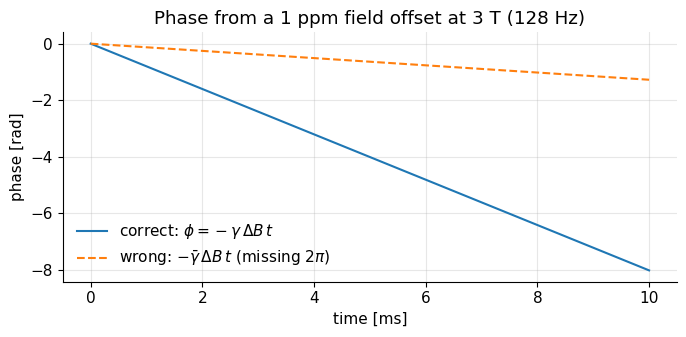

In [4]:
t = np.linspace(0, 10e-3, 200)           # time [s]
dB = 1e-6 * 3.0                          # 1 ppm field offset at 3 T [T]
phi_correct = -mt.GAMMA * dB * t         # [rad] = -2*pi*gamma_bar*dB*t
phi_wrong = -mt.GAMMA_BAR * dB * t       # missing 2*pi -> 6.28x too small

plt.figure(figsize=(7, 3.5))
plt.plot(t * 1e3, phi_correct, label=r"correct: $\phi=-\gamma\,\Delta B\,t$")
plt.plot(t * 1e3, phi_wrong, "--", label=r"wrong: $-\bar\gamma\,\Delta B\,t$ (missing $2\pi$)")
plt.xlabel("time [ms]"); plt.ylabel("phase [rad]")
plt.title("Phase from a 1 ppm field offset at 3 T (128 Hz)")
plt.legend(); plt.tight_layout(); plt.show()

Interpretation: after 10 ms a 128 Hz offset has turned $M_{xy}$ by $-2\pi\cdot128\cdot0.01\approx-8$ rad (1.3 full turns, clockwise); forgetting the $2\pi$ would predict only 1.3 rad. Always check whether a formula wants $\gamma$ (radians) or $\bar\gamma$ (cycles).

## Key takeaways

* Every symbol in this series is defined here with SI unit and typical value; chapter tables are local copies.
* $\gamma$ [rad s⁻¹ T⁻¹] vs $\bar\gamma=\gamma/2\pi$ [Hz/T]: phase uses $\gamma$, frequency and k-space use $\bar\gamma$.
* $T_1, T_2, T_2^*$ are time constants (s); $R_1, R_2, R_2^*$ are rates (s⁻¹). Magnetization is in A/m (normalized to $M_0=1$ in code).
* Precession is clockwise: $M_{xy}(t)=M_{xy}(0)e^{-i\omega t}$; Fourier kernel $e^{-i2\pi kx}$; $s(t)=M(\vec k(t))$.
* Watch for clashes: $T$, $I$, $\sigma$, $\delta$, $M$, $C$, $R$, $G$, $\lambda$, $*$, ADC.
* ppm × $\bar\gamma B_0$ gives Hz; 1 G/cm = 10 mT/m; dB is $10\log_{10}$ for power, $20\log_{10}$ for amplitude.

See also: [Glossary and acronyms](Glossary_and_Acronyms.ipynb) · [Key MRI concepts](Key_MRI_Concepts.ipynb) · [MRI math concepts](MRI_Math_Concepts.ipynb).

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "MRI Notation" (notation table, definitions and acronym links).
Changes: expanded from 11 to ~200 symbols grouped by topic with units, typical values and chapter links; added conventions, symbol clashes, units cheat sheet and a unit-converter; corrected "relaxation rates" → time constants, units of $\vec M$ ([T] → A/m), $I_Z$ → $I$, $k$ → $k_B$, $B_1$ in mT → µT, and $B_0(1+\sigma)$ → $B_0(1-\sigma)$.*